## Step 1 Load and Inspect 

In [1]:
import pandas as pd 
import numpy as np 

In [2]:
fx = pd.read_csv("EURUSD_daily.csv")

In [3]:
fx

,Date,Open,High,Low,Close
0,2003-12-01,1.20340,1.20401,1.19440,1.19650
1,2003-12-02,1.19610,1.21090,1.19460,1.20890
2,2003-12-03,1.20900,1.21300,1.20770,1.21230
3,2003-12-04,1.21200,1.21440,1.20440,1.20809
4,2003-12-05,1.20780,1.21910,1.20659,1.21869
...,...,...,...,...,...
5600,2025-07-01,1.18055,1.18100,1.17492,1.18055
5601,2025-07-02,1.18002,1.18133,1.17209,1.18002
5602,2025-07-03,1.17715,1.17869,1.17567,1.17715
5603,2025-07-06,1.17808,1.17901,1.17191,1.17808


In [4]:
print(fx.head())

         Date    Open     High      Low    Close
0  2003-12-01  1.2034  1.20401  1.19440  1.19650
1  2003-12-02  1.1961  1.21090  1.19460  1.20890
2  2003-12-03  1.2090  1.21300  1.20770  1.21230
3  2003-12-04  1.2120  1.21440  1.20440  1.20809
4  2003-12-05  1.2078  1.21910  1.20659  1.21869


In [5]:
print(fx.tail())

            Date     Open     High      Low    Close
5600  2025-07-01  1.18055  1.18100  1.17492  1.18055
5601  2025-07-02  1.18002  1.18133  1.17209  1.18002
5602  2025-07-03  1.17715  1.17869  1.17567  1.17715
5603  2025-07-06  1.17808  1.17901  1.17191  1.17808
5604  2025-07-07  1.17365  1.17648  1.16847  1.17365


In [6]:
print(fx.shape)

(5605, 5)


In [7]:
fx.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5605 entries, 0 to 5604
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    5605 non-null   object 
 1   Open    5605 non-null   float64
 2   High    5605 non-null   float64
 3   Low     5605 non-null   float64
 4   Close   5605 non-null   float64
dtypes: float64(4), object(1)
memory usage: 219.1+ KB


In [8]:
print(fx.isnull().sum())

Date     0
Open     0
High     0
Low      0
Close    0
dtype: int64


In [9]:
print(fx.duplicated().sum())

0


##  Step 2 Cleaning Data

In [10]:
fx.columns

Index(['Date', 'Open', 'High', 'Low', 'Close'], dtype='object')

# Left side is save coverted dates back into Date column

## Right side is save the current text and convert into actual Date

In [11]:
fx["Date"] = pd.to_datetime(fx["Date"])

## for this code the date  will be sort values from oldest data to new data

In [12]:
fx =fx.sort_values("Date" , ascending=True)
fx

,Date,Open,High,Low,Close
0,2003-12-01,1.20340,1.20401,1.19440,1.19650
1,2003-12-02,1.19610,1.21090,1.19460,1.20890
2,2003-12-03,1.20900,1.21300,1.20770,1.21230
3,2003-12-04,1.21200,1.21440,1.20440,1.20809
4,2003-12-05,1.20780,1.21910,1.20659,1.21869
...,...,...,...,...,...
5600,2025-07-01,1.18055,1.18100,1.17492,1.18055
5601,2025-07-02,1.18002,1.18133,1.17209,1.18002
5602,2025-07-03,1.17715,1.17869,1.17567,1.17715
5603,2025-07-06,1.17808,1.17901,1.17191,1.17808


- (C)  Remove all duplicate row from fx

In [13]:
fx =fx.drop_duplicates()
fx

,Date,Open,High,Low,Close
0,2003-12-01,1.20340,1.20401,1.19440,1.19650
1,2003-12-02,1.19610,1.21090,1.19460,1.20890
2,2003-12-03,1.20900,1.21300,1.20770,1.21230
3,2003-12-04,1.21200,1.21440,1.20440,1.20809
4,2003-12-05,1.20780,1.21910,1.20659,1.21869
...,...,...,...,...,...
5600,2025-07-01,1.18055,1.18100,1.17492,1.18055
5601,2025-07-02,1.18002,1.18133,1.17209,1.18002
5602,2025-07-03,1.17715,1.17869,1.17567,1.17715
5603,2025-07-06,1.17808,1.17901,1.17191,1.17808


In [14]:
fx.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5605 entries, 0 to 5604
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    5605 non-null   datetime64[ns]
 1   Open    5605 non-null   float64       
 2   High    5605 non-null   float64       
 3   Low     5605 non-null   float64       
 4   Close   5605 non-null   float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 219.1 KB


In [15]:
#close price cannot be zero or below is impossible , so replace with nan

In [16]:
fx.loc[(fx["Close"]<=0) , "Close"] =np.nan

In [17]:
#fill the missing value in close using forward fill 

In [18]:
fx["Close"] = fx["Close"].ffill()

In [19]:
print(fx.isnull().sum())

Date     0
Open     0
High     0
Low      0
Close    0
dtype: int64


In [20]:
fx.to_csv("EURUSD_clean.csv" , index = False)

# Step 3 Feature Engineering 

a: create a new column Range = High minus Low

In [21]:
fx["Range"] = fx["High"]- fx["Low"]
fx["Range"]

0       0.00961
1       0.01630
2       0.00530
3       0.01000
4       0.01251
         ...   
5600    0.00608
5601    0.00924
5602    0.00302
5603    0.00710
5604    0.00801
Name: Range, Length: 5605, dtype: float64

- b : close the day before and give the change as a decimal 

In [22]:
fx["Return"] = fx["Close"].pct_change() *100 
fx["Return"]

0            NaN
1       1.036356
2       0.281247
3      -0.347274
4       0.877418
          ...   
5600    0.155253
5601   -0.044894
5602   -0.243216
5603    0.079004
5604   -0.376036
Name: Return, Length: 5605, dtype: float64

- c: Create a new column Direction that labels a day "up" when Close is greater than Open, and "down" otherwise

In [23]:
#for each days if close is higher than open the price will went up , so the label is up otherwise is down
fx["Direction"] = np.where(fx["Return"] > 0, "up","down")
fx["Direction"]

0       down
1         up
2         up
3       down
4         up
        ... 
5600      up
5601    down
5602    down
5603      up
5604    down
Name: Direction, Length: 5605, dtype: object

- dt mean date tool

In [24]:
## Create a column Year from Date 
fx["Year"] = fx["Date"].dt.year

In [25]:
print(fx["Direction"].value_counts())

Direction
down    2815
up      2790
Name: count, dtype: int64


In [26]:
print(fx.head())

        Date    Open     High      Low    Close    Range    Return Direction  \
0 2003-12-01  1.2034  1.20401  1.19440  1.19650  0.00961       NaN      down   
1 2003-12-02  1.1961  1.21090  1.19460  1.20890  0.01630  1.036356        up   
2 2003-12-03  1.2090  1.21300  1.20770  1.21230  0.00530  0.281247        up   
3 2003-12-04  1.2120  1.21440  1.20440  1.20809  0.01000 -0.347274      down   
4 2003-12-05  1.2078  1.21910  1.20659  1.21869  0.01251  0.877418        up   

   Year  
0  2003  
1  2003  
2  2003  
3  2003  
4  2003  


# Step 4 Statistics

In [27]:
print(fx.describe())

                                Date         Open         High          Low  \
count                           5605  5605.000000  5605.000000  5605.000000   
mean   2014-09-25 10:12:13.487957248     1.226195     1.230720     1.221296   
min              2003-12-01 00:00:00     0.959620     0.967010     0.072900   
25%              2009-05-17 00:00:00     1.115820     1.119760     1.112400   
50%              2014-10-01 00:00:00     1.211400     1.215410     1.206510   
75%              2020-02-19 00:00:00     1.322400     1.328000     1.316840   
max              2025-07-07 00:00:00     1.598180     1.602820     1.587400   
std                              NaN     0.128402     0.129173     0.128573   

             Close        Range       Return         Year  
count  5605.000000  5605.000000  5604.000000  5605.000000  
mean      1.226217     0.009425     0.002124  2014.239964  
min       0.959620     0.000000   -13.352326  2003.000000  
25%       1.115850     0.005420    -0.317650  20

- The Average of  Yearly Return 

In [28]:
print(fx.groupby("Year")["Return"].mean())

Year
2003    0.232371
2004    0.030913
2005   -0.050917
2006    0.042913
2007    0.039932
2008    0.005263
2009    0.012401
2010   -0.025701
2011   -0.007173
2012    0.009489
2013    0.017863
2014   -0.047909
2015   -0.037796
2016   -0.011394
2017    0.048150
2018   -0.015443
2019   -0.007552
2020    0.036774
2021   -0.031013
2022   -0.021354
2023    0.015546
2024   -0.022862
2025    0.092933
Name: Return, dtype: float64


- (C) the average Range for each direction 

In [29]:
print(fx.groupby("Direction")["Range"].mean())

Direction
down    0.009199
up      0.009652
Name: Range, dtype: float64


In [30]:
#Using IQR Method to know trading pair normally how they move every day 

In [31]:
Q1 = fx["Range"].quantile(0.25)
Q3 = fx["Range"].quantile(0.75)

IQR = Q3 -Q1
print(IQR , Q1 , Q3)

0.005779999999999896 0.00541999999999998 0.011199999999999877


In [32]:
print((fx["Open"] == fx["Close"]).sum())

1255


In [33]:
print(fx.sort_values("Return" , ascending=False ).head())

           Date     Open     High      Low    Close    Range     Return  \
1286 2008-12-08  1.48989  1.49640  1.48181  1.49180  0.01459  17.307541   
1243 2008-10-07  1.50500  1.50500  1.49140  1.49571  0.01360  10.074992   
1089 2008-02-08  1.55710  1.55710  1.55410  1.55710  0.00300   7.542700   
1066 2008-01-08  1.55921  1.55928  1.55299  1.55710  0.00629   6.047810   
1221 2008-09-07  1.50489  1.50500  1.50401  1.50500  0.00099   5.429810   

     Direction  Year  
1286        up  2008  
1243        up  2008  
1089        up  2008  
1066        up  2008  
1221        up  2008  


In [34]:
print(fx[fx["Open"] == fx["Close"]]["Year"].value_counts())

Year
2023    259
2024    258
2022    204
2025    132
2012    121
2013     54
2016     44
2014     34
2015     23
2019     20
2011     18
2018     18
2021     15
2009     14
2020     13
2017     11
2010      6
2008      4
2007      3
2004      2
2005      1
2006      1
Name: count, dtype: int64


In [35]:
print(fx[fx["Return"].abs() > 3])

           Date     Open     High      Low    Close    Range     Return  \
1066 2008-01-08  1.55921  1.55928  1.55299  1.55710  0.00629   6.047810   
1067 2008-01-09  1.47070  1.47399  1.46430  1.46640  0.00969  -5.824931   
1089 2008-02-08  1.55710  1.55710  1.55410  1.55710  0.00300   7.542700   
1090 2008-02-11  1.45319  1.45770  1.44860  1.45020  0.00910  -6.865327   
1211 2008-08-07  1.53341  1.53360  1.49999  1.50489  0.03361  -3.490005   
1221 2008-09-07  1.50489  1.50500  1.50401  1.50500  0.00099   5.429810   
1222 2008-09-08  1.41521  1.42250  1.40550  1.41485  0.01700  -5.990033   
1243 2008-10-07  1.50500  1.50500  1.49140  1.49571  0.01360  10.074992   
1244 2008-10-08  1.36290  1.37838  1.35842  1.35980  0.01996  -9.086654   
1286 2008-12-08  1.48989  1.49640  1.48181  1.49180  0.01459  17.307541   
1287 2008-12-09  1.29141  1.29960  1.28090  1.29261  0.01870 -13.352326   
1358 2009-03-18  1.30341  1.35300  1.29929  1.34840  0.05371   3.458859   
2483 2013-07-10  1.31764 

In [41]:
fx = fx[fx["Return"].abs()<5].copy()
fx

,Date,Open,High,Low,Close,Range,Return,Direction,Year
2,2003-12-03,1.20900,1.21300,1.20770,1.21230,0.00530,0.281247,up,2003
3,2003-12-04,1.21200,1.21440,1.20440,1.20809,0.01000,-0.347274,down,2003
4,2003-12-05,1.20780,1.21910,1.20659,1.21869,0.01251,0.877418,up,2003
5,2003-12-08,1.21680,1.22401,1.21541,1.22200,0.00860,0.271603,up,2003
6,2003-12-09,1.22211,1.22770,1.21979,1.22499,0.00791,0.244681,up,2003
...,...,...,...,...,...,...,...,...,...
5600,2025-07-01,1.18055,1.18100,1.17492,1.18055,0.00608,0.155253,up,2025
5601,2025-07-02,1.18002,1.18133,1.17209,1.18002,0.00924,-0.044894,down,2025
5602,2025-07-03,1.17715,1.17869,1.17567,1.17715,0.00302,-0.243216,down,2025
5603,2025-07-06,1.17808,1.17901,1.17191,1.17808,0.00710,0.079004,up,2025


In [42]:
fx["Return"] = fx["Close"].pct_change()*100
fx["Return"]

2            NaN
3      -0.347274
4       0.877418
5       0.271603
6       0.244681
          ...   
5600    0.155253
5601   -0.044894
5602   -0.243216
5603    0.079004
5604   -0.376036
Name: Return, Length: 5593, dtype: float64

In [44]:
print(fx[fx["Return"].abs()>3])

           Date     Open     High      Low    Close    Range    Return  \
1211 2008-08-07  1.53341  1.53360  1.49999  1.50489  0.03361 -3.490005   
1358 2009-03-18  1.30341  1.35300  1.29929  1.34840  0.05371  3.458859   
2483 2013-07-10  1.31764  1.31764  1.30089  1.31877  0.01675  3.175609   

     Direction  Year  
1211      down  2008  
1358        up  2009  
2483        up  2013  


In [52]:
print(fx.sort_values("Return" , ascending=False).head())

           Date     Open     High      Low    Close    Range    Return  \
1358 2009-03-18  1.30341  1.35300  1.29929  1.34840  0.05371  3.458859   
2483 2013-07-10  1.31764  1.31764  1.30089  1.31877  0.01675  3.175609   
1262 2008-11-04  1.26202  1.30460  1.25302  1.29840  0.05158  2.900618   
3108 2015-12-04  1.09183  1.09519  1.08580  1.09160  0.00939  2.854989   
5544 2025-04-10  1.12578  1.14718  1.12509  1.12578  0.02209  2.791246   

     Direction  Year  
1358        up  2009  
2483        up  2013  
1262        up  2008  
3108        up  2015  
5544        up  2025  


# Step 5 input MA Strategy 

In [54]:
fx["MA20"] = fx["Close"].rolling(20).mean()
fx["MA20"]

2            NaN
3            NaN
4            NaN
5            NaN
6            NaN
          ...   
5600    1.156239
5601    1.158130
5602    1.159718
5603    1.161583
5604    1.163126
Name: MA20, Length: 5593, dtype: float64

In [55]:
fx["MA50"] = fx["Close"].rolling(50).mean()
fx["MA50"]

2            NaN
3            NaN
4            NaN
5            NaN
6            NaN
          ...   
5600    1.140658
5601    1.141603
5602    1.142403
5603    1.143278
5604    1.143933
Name: MA50, Length: 5593, dtype: float64

In [56]:
import numpy as np

In [58]:
fx["Signal"] = np.where( fx["MA20"] > fx["MA50"] , "buy" , "sell")
fx["Signal"]

2       sell
3       sell
4       sell
5       sell
6       sell
        ... 
5600     buy
5601     buy
5602     buy
5603     buy
5604     buy
Name: Signal, Length: 5593, dtype: object

In [60]:
fx["Strategy_Return"] = fx["Return"].shift(1)
fx["Strategy_Return"]

2            NaN
3            NaN
4      -0.347274
5       0.877418
6       0.271603
          ...   
5600    0.509060
5601    0.155253
5602   -0.044894
5603   -0.243216
5604    0.079004
Name: Strategy_Return, Length: 5593, dtype: float64

- now i will count how many buy and sell trade while backtesting Ma

In [67]:
print(fx["Signal"].value_counts())

Signal
sell    2847
buy     2746
Name: count, dtype: int64


In [82]:
print(fx.groupby("Signal")["Strategy_Return"].mean())

Signal
buy     0.012959
sell   -0.010203
Name: Strategy_Return, dtype: float64


# Step 6 Charts

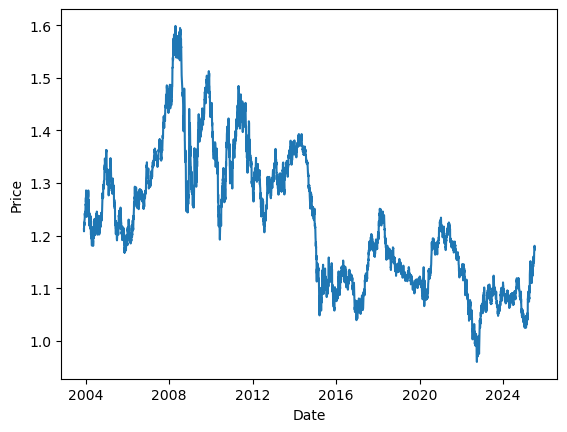

In [88]:
import matplotlib.pyplot as plt 

plt.plot(fx["Date"],fx["Close"])
plt.xlabel("Date")
plt.ylabel("Price")
plt.show()

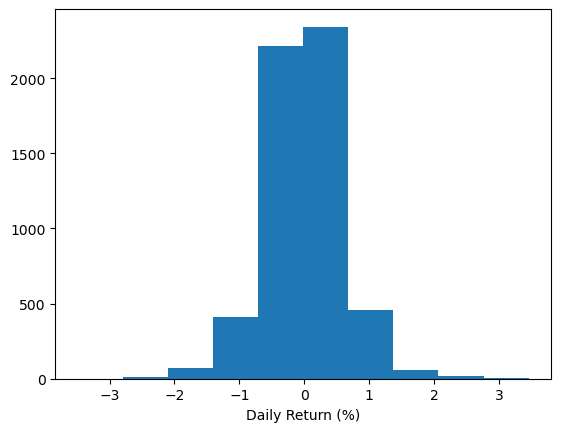

In [89]:
plt.hist(fx["Return"])
plt.xlabel("Daily Return (%)")
plt.show()

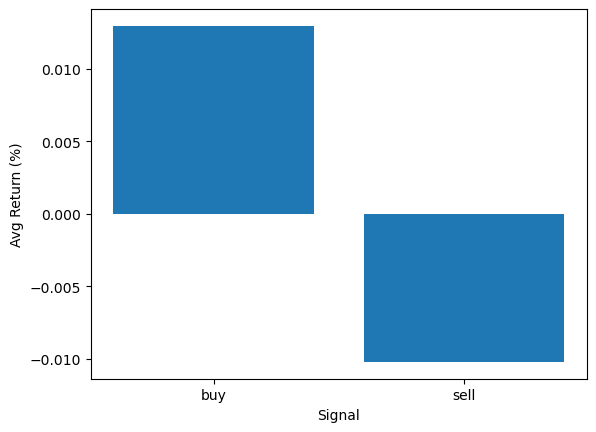

In [91]:
counts = fx.groupby("Signal")["Strategy_Return"].mean()
plt.bar(counts.index,counts.values)
plt.xlabel("Signal")
plt.ylabel("Avg Return (%)")
plt.show()